<a href="https://colab.research.google.com/github/MuthumalarG/Intelligent-Attention-Assessment/blob/main/Copy_of_Online_Meetings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import os
import hashlib
from collections import defaultdict

dataset_path = "/content/drive/MyDrive/Student-engagement-dataset"

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
hash_to_files = defaultdict(list)
total_images = 0

for root, dirs, files in os.walk(dataset_path):
    for filename in files:
        if filename.lower().endswith(image_extensions):
            file_path = os.path.join(root, filename)
            total_images += 1

            with open(file_path, "rb") as image_file:
                image_hash = hashlib.sha256(
                    image_file.read()
                ).hexdigest()

            hash_to_files[image_hash].append(
                os.path.relpath(file_path, dataset_path)
            )

duplicate_groups = {
    image_hash: paths
    for image_hash, paths in hash_to_files.items()
    if len(paths) > 1
}

print("Total images checked:", total_images)
print("Exact duplicate groups:", len(duplicate_groups))

if duplicate_groups:
    for number, paths in enumerate(
        duplicate_groups.values(), start=1
    ):
        print(f"\nDuplicate group {number}:")
        for path in paths:
            print(" -", path)
else:
    print("No exact duplicate files found.")


Total images checked: 2120
Exact duplicate groups: 35

Duplicate group 1:
 - Not Engaged/Bored/0068.jpg
 - Not Engaged/Drowsy/0068.jpg

Duplicate group 2:
 - Not Engaged/Bored/0144.jpg
 - Not Engaged/Drowsy/0144.jpg

Duplicate group 3:
 - Not Engaged/Bored/0073.jpg
 - Not Engaged/Drowsy/0073.jpg

Duplicate group 4:
 - Not Engaged/Bored/0150.jpg
 - Not Engaged/Drowsy/0150.jpg

Duplicate group 5:
 - Not Engaged/Bored/0145.jpg
 - Not Engaged/Drowsy/0145.jpg

Duplicate group 6:
 - Not Engaged/Bored/0091.jpg
 - Not Engaged/Drowsy/0091.jpg

Duplicate group 7:
 - Not Engaged/Bored/0075.jpg
 - Not Engaged/Drowsy/0075.jpg

Duplicate group 8:
 - Not Engaged/Bored/0149.jpg
 - Not Engaged/Drowsy/0149.jpg

Duplicate group 9:
 - Not Engaged/Bored/0090.jpg
 - Not Engaged/Drowsy/0090.jpg

Duplicate group 10:
 - Not Engaged/Bored/0146.jpg
 - Not Engaged/Drowsy/0146.jpg

Duplicate group 11:
 - Not Engaged/Bored/0151.jpg
 - Not Engaged/Drowsy/0151.jpg

Duplicate group 12:
 - Not Engaged/Bored/0074.jpg
 -

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

In [ ]:
dataset_path = "/content/drive/MyDrive/Student-engagement-dataset"
print(os.listdir(dataset_path))

['Engaged', 'Not Engaged']


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path, validation_split=0.2, subset="training",
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE
)

validation_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path, validation_split=0.2, subset="validation",
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE
)

class_names = train_dataset.class_names
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)

Found 2120 files belonging to 2 classes.
Using 1696 files for training.
Found 2120 files belonging to 2 classes.
Using 424 files for validation.
Classes: ['Engaged', 'Not Engaged']


In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

In [ ]:
def build_transfer_model(base_model_fn, preprocess_fn, name):
    base_model = base_model_fn(
        weights='imagenet', include_top=False, input_shape=(224, 224, 3)
    )
    base_model.trainable = False

    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs)
    x = preprocess_fn(x)          # each architecture's OWN correct preprocessing
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = tf.keras.Model(inputs, outputs, name=name)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

In [ ]:
def evaluate_model(model, dataset, model_name):
    y_true, y_prob = [], []
    for images, labels in dataset:
        preds = model.predict(images, verbose=0).ravel()
        y_prob.extend(preds)
        y_true.extend(labels.numpy())

    y_true = np.array(y_true).astype(int)
    y_pred = (np.array(y_prob) >= 0.5).astype(int)

    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    print(f"\n===== {model_name} =====")
    print(f"Accuracy : {acc*100:.2f}%")
    print(f"Precision: {prec*100:.2f}%")
    print(f"Recall   : {rec*100:.2f}%")
    print(f"F1-score : {f1*100:.2f}%")
    print("\nConfusion Matrix:\n", confusion_matrix(y_true, y_pred))
    print("\nClassification Report:\n", classification_report(y_true, y_pred, target_names=class_names, digits=4))

    return {"Model": model_name, "Accuracy": acc*100, "Precision": prec*100, "Recall": rec*100, "F1-score": f1*100}

In [ ]:
from tensorflow.keras.applications import MobileNetV2, ResNet50, EfficientNetB0
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mnv2_preprocess

early_stop = EarlyStopping(monitor='val_accuracy', patience=2, restore_best_weights=True)

mobilenet_model = build_transfer_model(MobileNetV2, mnv2_preprocess, "MobileNetV2")
mobilenet_history = mobilenet_model.fit(
    train_dataset, validation_data=validation_dataset, epochs=10, callbacks=[early_stop]
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 777s 14s/step - accuracy: 0.8909 - loss: 0.2704 - val_accuracy: 0.9340 - val_loss: 0.1331
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 8s 148ms/step - accuracy: 0.9823 - loss: 0.0593 - val_accuracy: 0.9953 - val_loss: 0.0514
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 9s 120ms/step - accuracy: 0.9876 - loss: 0.0402 - val_accuracy: 0.9835 - val_loss: 0.0507
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - accuracy: 0.9912 - loss: 0.0266 - val_accuracy: 0.9953 - val_loss: 0.0243


In [ ]:
mobilenet_results = evaluate_model(mobilenet_model, validation_dataset, "MobileNetV2")


===== MobileNetV2 =====
Accuracy : 99.53%
Precision: 99.13%
Recall   : 100.00%
F1-score : 99.57%

Confusion Matrix:
 [[193   2]
 [  0 229]]

Classification Report:
               precision    recall  f1-score   support

     Engaged     1.0000    0.9897    0.9948       195
 Not Engaged     0.9913    1.0000    0.9957       229

    accuracy                         0.9953       424
   macro avg     0.9957    0.9949    0.9952       424
weighted avg     0.9953    0.9953    0.9953       424



In [ ]:
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

resnet_model = build_transfer_model(ResNet50, resnet_preprocess, "ResNet50")
resnet_history = resnet_model.fit(
    train_dataset, validation_data=validation_dataset, epochs=10, callbacks=[early_stop]
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 21s 223ms/step - accuracy: 0.9033 - loss: 0.2420 - val_accuracy: 0.9623 - val_loss: 0.1001
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 180ms/step - accuracy: 0.9841 - loss: 0.0544 - val_accuracy: 0.9693 - val_loss: 0.0699


In [ ]:
resnet_results = evaluate_model(resnet_model, validation_dataset, "ResNet50")


===== ResNet50 =====
Accuracy : 96.23%
Precision: 99.08%
Recall   : 93.89%
F1-score : 96.41%

Confusion Matrix:
 [[193   2]
 [ 14 215]]

Classification Report:
               precision    recall  f1-score   support

     Engaged     0.9324    0.9897    0.9602       195
 Not Engaged     0.9908    0.9389    0.9641       229

    accuracy                         0.9623       424
   macro avg     0.9616    0.9643    0.9622       424
weighted avg     0.9639    0.9623    0.9623       424



In [ ]:
import tensorflow as tf
print("GPU available:", tf.config.list_physical_devices('GPU'))

GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from tensorflow.keras.applications.efficientnet import preprocess_input as effnet_preprocess

efficientnet_model = build_transfer_model(EfficientNetB0, effnet_preprocess, "EfficientNet-B0")
efficientnet_history = efficientnet_model.fit(
    train_dataset, validation_data=validation_dataset, epochs=10, callbacks=[early_stop]
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 186ms/step - accuracy: 0.9080 - loss: 0.2320 - val_accuracy: 0.9717 - val_loss: 0.0982
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 8s 145ms/step - accuracy: 0.9805 - loss: 0.0607 - val_accuracy: 0.9717 - val_loss: 0.0757


In [ ]:
efficientnet_results = evaluate_model(efficientnet_model, validation_dataset, "EfficientNet-B0")


===== EfficientNet-B0 =====
Accuracy : 97.17%
Precision: 97.80%
Recall   : 96.94%
F1-score : 97.37%

Confusion Matrix:
 [[190   5]
 [  7 222]]

Classification Report:
               precision    recall  f1-score   support

     Engaged     0.9645    0.9744    0.9694       195
 Not Engaged     0.9780    0.9694    0.9737       229

    accuracy                         0.9717       424
   macro avg     0.9712    0.9719    0.9715       424
weighted avg     0.9718    0.9717    0.9717       424



,Model,Accuracy,Precision,Recall,F1-score
0,MobileNetV2,99.528302,99.134199,100.000000,99.565217
1,ResNet50,96.226415,99.078341,93.886463,96.412556
2,EfficientNet-B0,97.169811,97.797357,96.943231,97.368421


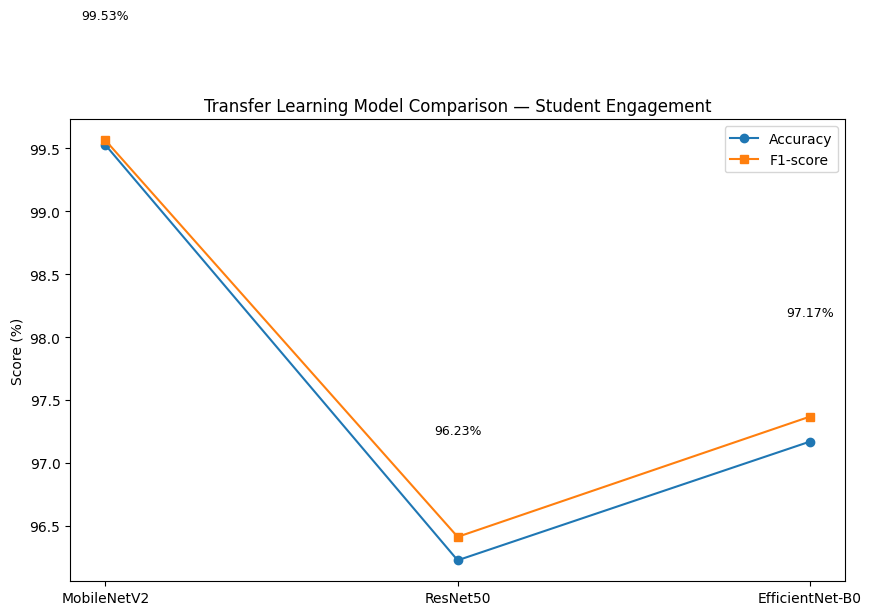


Best performing model: MobileNetV2


In [ ]:
comparison_df = pd.DataFrame([mobilenet_results, resnet_results, efficientnet_results])
display(comparison_df)

plt.figure(figsize=(10, 6))
plt.plot(comparison_df["Model"], comparison_df["Accuracy"], marker='o', label="Accuracy")
plt.plot(comparison_df["Model"], comparison_df["F1-score"], marker='s', label="F1-score")
for i, row in comparison_df.iterrows():
    plt.text(i, row["Accuracy"] + 1, f"{row['Accuracy']:.2f}%", ha='center', fontsize=9)
plt.ylabel("Score (%)")
plt.title("Transfer Learning Model Comparison — Student Engagement")
plt.legend()
plt.show()

best_model_name = comparison_df.loc[comparison_df["Accuracy"].idxmax(), "Model"]
print(f"\nBest performing model: {best_model_name}")

In [ ]:
mobilenet_model.save("mobilenet_engagement_model.keras")
from google.colab import files
files.download("mobilenet_engagement_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

uploaded = files.upload()
img_path = list(uploaded.keys())[0]   # picks the file you just uploaded

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image

# use the model you want to test with — mobilenet_model, resnet_model, or efficientnet_model
model_to_use = mobilenet_model

img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)   # preprocessing is already built into the model, so don't rescale here

prediction = model_to_use.predict(img_array, verbose=0)
score = float(prediction[0][0])

# class_names[0] and class_names[1] come from your dataset folders (alphabetical order)
predicted_class = class_names[int(score > 0.5)]
confidence = score * 100 if score > 0.5 else (1 - score) * 100

print("="*40)
print("STUDENT ENGAGEMENT PREDICTION")
print("="*40)
print("Predicted Class :", predicted_class)
print("Confidence      :", round(confidence, 2), "%")
print("Raw Score       :", round(score, 4))
print("="*40)

STUDENT ENGAGEMENT PREDICTION
Predicted Class : Engaged
Confidence      : 98.85 %
Raw Score       : 0.0115


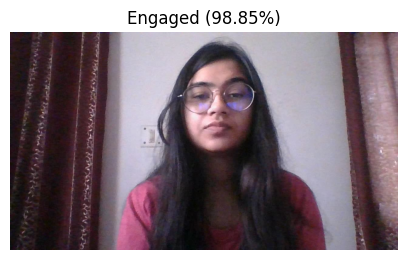

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

img_display = Image.open(img_path)

plt.figure(figsize=(5, 5))
plt.imshow(img_display)
plt.title(f"{predicted_class} ({round(confidence, 2)}%)")
plt.axis("off")
plt.show()

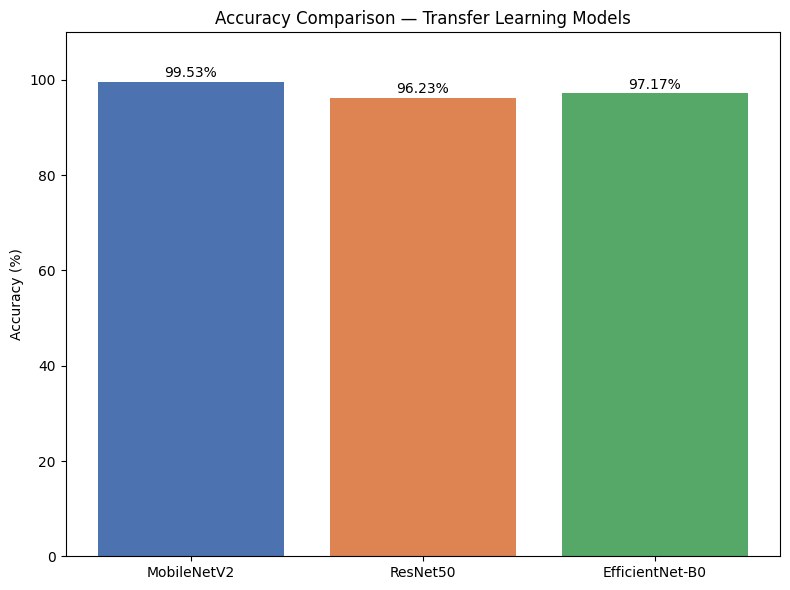

In [ ]:
import matplotlib.pyplot as plt

results_list = [mobilenet_results, resnet_results, efficientnet_results]
model_names = [r["Model"] for r in results_list]
accuracies = [r["Accuracy"] for r in results_list]

plt.figure(figsize=(8, 6))
bars = plt.bar(model_names, accuracies, color=['#4C72B0', '#DD8452', '#55A868'])

for bar, val in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, val + 1, f"{val:.2f}%",
              ha='center', fontsize=10)

plt.ylabel("Accuracy (%)")
plt.ylim(0, 110)
plt.title("Accuracy Comparison — Transfer Learning Models")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

comparison_df = pd.DataFrame([mobilenet_results, resnet_results, efficientnet_results])
comparison_df = comparison_df[["Model", "Accuracy", "Precision", "Recall", "F1-score"]]
comparison_df = comparison_df.round(2)

print("Model Comparison — Engaged vs Not Engaged Classification")
display(comparison_df)

Model Comparison — Engaged vs Not Engaged Classification


,Model,Accuracy,Precision,Recall,F1-score
0,MobileNetV2,99.53,99.13,100.00,99.57
1,ResNet50,96.23,99.08,93.89,96.41
2,EfficientNet-B0,97.17,97.80,96.94,97.37


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def plot_confusion_matrix(model, dataset, model_name, class_names):
    y_true, y_prob = [], []
    for images, labels in dataset:
        preds = model.predict(images, verbose=0).ravel()
        y_prob.extend(preds)
        y_true.extend(labels.numpy())

    y_true = np.array(y_true).astype(int)
    y_pred = (np.array(y_prob) >= 0.5).astype(int)

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix — {model_name}")
    plt.tight_layout()
    plt.show()

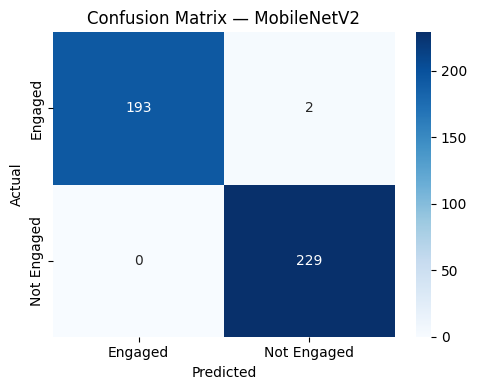

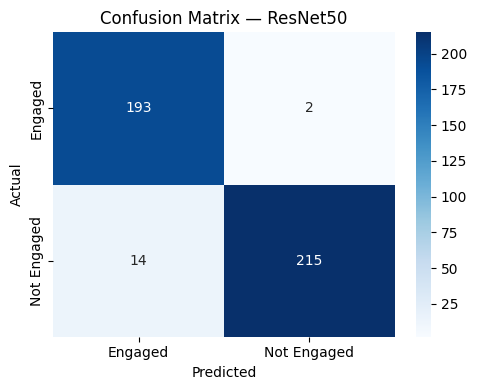

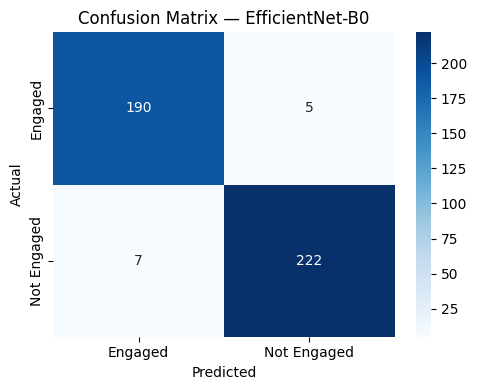

In [ ]:
plot_confusion_matrix(mobilenet_model, validation_dataset, "MobileNetV2", class_names)
plot_confusion_matrix(resnet_model, validation_dataset, "ResNet50", class_names)
plot_confusion_matrix(efficientnet_model, validation_dataset, "EfficientNet-B0", class_names)

In [ ]:
import os, json, tensorflow as tf
from google.colab import drive
drive.mount('/content/drive')

APP_DIR = "/content/drive/MyDrive/engagement_app"
print(os.listdir(APP_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['mobilenet_engagement.keras', 'class_names.json', 'requirements.txt', '.streamlit', 'app.py']


In [ ]:
!pip install -q streamlit
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
!dpkg -i cloudflared-linux-amd64.deb

Selecting previously unselected package cloudflared.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack cloudflared-linux-amd64.deb ...
Unpacking cloudflared (2026.10.7) ...
Setting up cloudflared (2026.10.7) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [ ]:
import os
APP = "/content/drive/MyDrive/engagement_app"
os.makedirs(f"{APP}/.streamlit", exist_ok=True)

open(f"{APP}/.streamlit/config.toml", "w").write("""[theme]
base = "dark"
primaryColor = "#4F46E5"
backgroundColor = "#0B1020"
secondaryBackgroundColor = "#1B2236"
textColor = "#FFFFFF"
""")

open(f"{APP}/app.py", "w").write('''
import json
import numpy as np
import streamlit as st
import tensorflow as tf
from PIL import Image, ImageOps

st.set_page_config(page_title="AI Attention Assessment", page_icon="🧠", layout="wide")

@st.cache_resource
def load():
    m = tf.keras.models.load_model("/content/drive/MyDrive/engagement_app/mobilenet_engagement.keras")
    names = json.load(open("/content/drive/MyDrive/engagement_app/class_names.json"))
    return m, names

model, class_names = load()
ENGAGED_IDX = class_names.index("Engaged")

def analyze(img):
    img = ImageOps.exif_transpose(img).convert("RGB").resize((224, 224))
    arr = np.array(img, dtype="float32")
    p1 = float(model.predict(arr[None], verbose=0)[0][0])
    pe = [1 - p1, p1][ENGAGED_IDX]
    label = "Engaged" if pe >= 0.5 else "Not Engaged"
    conf, score = max(pe, 1 - pe) * 100, pe * 100
    if score >= 80:   rec = "Student is highly attentive. Keep the current teaching pace."
    elif score >= 50: rec = "Student is moderately attentive. Consider asking a question to re-engage."
    elif score >= 20: rec = "Student appears distracted. Try an interactive activity or a short break."
    else:             rec = "Student is clearly disengaged. Direct interaction is recommended."
    return label, conf, score, rec

st.title("🧠 AI Attention Assessment")
st.write("Analyze student engagement using MobileNetV2. Upload a student image to get the prediction.")

left, right = st.columns(2)
with left:
    file = st.file_uploader("Upload Student Image", type=["jpg", "jpeg", "png"])
    if file:
        st.image(file, use_container_width=True)
    run = st.button("🔍 Analyze Attention", type="primary", use_container_width=True)

with right:
    if run and file:
        label, conf, score, rec = analyze(Image.open(file))
        st.subheader("Predicted Attention State")
        (st.success if label == "Engaged" else st.error)(label)
        st.subheader("Confidence");       st.info(f"{conf:.2f}%")
        st.subheader("Attention Score");  st.info(f"{score:.1f} / 100")
        st.progress(int(score))
        st.subheader("Recommendation");   st.info(rec)
    else:
        st.subheader("Predicted Attention State"); st.info("No image")
        st.subheader("Confidence");       st.info("N/A")
        st.subheader("Attention Score");  st.info("N/A")
        st.subheader("Recommendation");   st.info("Please upload a student's image.")
''')
print(os.listdir(APP))

['mobilenet_engagement.keras', 'class_names.json', 'requirements.txt', '.streamlit', 'app.py']


In [ ]:
import subprocess, time, re, os

subprocess.run("pkill -f streamlit; pkill -f cloudflared", shell=True)
subprocess.Popen("cd /content/drive/MyDrive/engagement_app && "
                 "streamlit run app.py --server.port 8501 --server.headless true > /content/st.log 2>&1",
                 shell=True)
time.sleep(8)
subprocess.Popen("cloudflared tunnel --url http://localhost:8501 > /content/cf.log 2>&1", shell=True)

url = None
for _ in range(30):
    time.sleep(2)
    m = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", open("/content/cf.log").read())
    if m:
        url = m.group(0)
        break
print("Open this link:", url or "not ready, run this cell again")

Open this link: https://mission-robust-smaller-forty.trycloudflare.com
